Saving image.jpg to image (2).jpg

Padding methods:
1. Zero Padding
2. Replication Padding
3. Reflection Padding
Enter padding method: 3
Enter filter size (odd number): 9

Choose filter:
1. Averaging Filter
2. Weighted Filter
3. Gaussian Filter
Enter your choice: 1

Original Image:


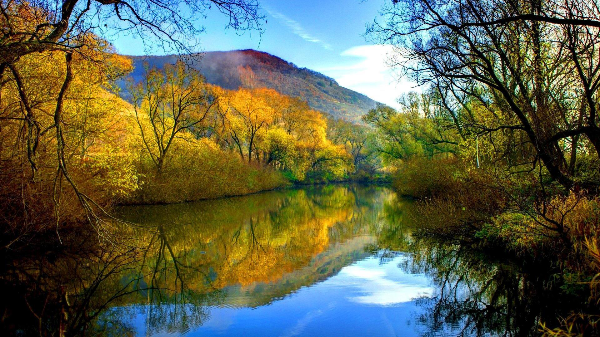

Averaging Filter:


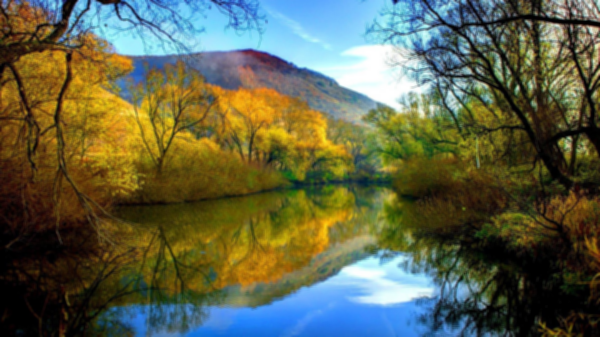


Smoothing completed!
Output saved as smoothed_image.jpg


In [10]:

import cv2
import numpy as np
from google.colab import files
from google.colab.patches import cv2_imshow


# ---------------- PADDING ----------------
def pad_image(img, pad, method):

    if method == 1:          # Zero padding
        return np.pad(img, ((pad, pad), (pad, pad), (0, 0)),
                      mode='constant', constant_values=0)

    elif method == 2:        # Replication padding
        return np.pad(img, ((pad, pad), (pad, pad), (0, 0)),
                      mode='edge')

    elif method == 3:        # Reflection padding
        return np.pad(img, ((pad, pad), (pad, pad), (0, 0)),
                      mode='reflect')

    else:
        print("Invalid padding method!")
        return None


# ---------------- AVERAGING FILTER ----------------
def averaging_filter(img, size, padding):

    pad = size // 2
    padded = pad_image(img, pad, padding)

    result = np.zeros_like(img, dtype=np.float64)

    for i in range(img.shape[0]):
        for j in range(img.shape[1]):

            window = padded[i:i+size, j:j+size]

            result[i, j] = np.mean(window, axis=(0, 1))

    return np.uint8(np.clip(result, 0, 255))


# ---------------- WEIGHTED FILTER ----------------
def weighted_filter(img, size, padding):

    pad = size // 2
    padded = pad_image(img, pad, padding)

    r = np.arange(-pad, pad + 1)
    x, y = np.meshgrid(r, r)

    # h(x,y) = max(|x|, |y|)
    kernel = np.maximum(np.abs(x), np.abs(y)).astype(float)

    # Center weight cannot be zero
    kernel[pad, pad] = 1

    # Normalize
    kernel = kernel / np.sum(kernel)

    result = np.zeros_like(img, dtype=np.float64)

    for i in range(img.shape[0]):
        for j in range(img.shape[1]):

            window = padded[i:i+size, j:j+size]

            for c in range(3):
                result[i, j, c] = np.sum(
                    window[:, :, c] * kernel
                )

    return np.uint8(np.clip(result, 0, 255))


# ---------------- GAUSSIAN FILTER ----------------
def gaussian_filter(img, size, sigma, padding):

    pad = size // 2
    padded = pad_image(img, pad, padding)

    r = np.arange(-pad, pad + 1)
    x, y = np.meshgrid(r, r)

    # Gaussian kernel
    kernel = np.exp(
        -(x**2 + y**2) / (2 * sigma**2)
    )

    # Normalize
    kernel = kernel / np.sum(kernel)

    result = np.zeros_like(img, dtype=np.float64)

    for i in range(img.shape[0]):
        for j in range(img.shape[1]):

            window = padded[i:i+size, j:j+size]

            for c in range(3):
                result[i, j, c] = np.sum(
                    window[:, :, c] * kernel
                )

    return np.uint8(np.clip(result, 0, 255))


# ---------------- IMAGE UPLOAD ----------------
uploaded = files.upload()

image_path = list(uploaded.keys())[0]

img = cv2.imread(image_path)

if img is None:
    print("Image not found!")
    exit()


# ---------------- MAIN PROGRAM ----------------
print("\nPadding methods:")
print("1. Zero Padding")
print("2. Replication Padding")
print("3. Reflection Padding")

padding = int(input("Enter padding method: "))

size = int(input("Enter filter size (odd number): "))

if size % 2 == 0:
    print("Filter size must be odd!")
    exit()


print("\nChoose filter:")
print("1. Averaging Filter")
print("2. Weighted Filter")
print("3. Gaussian Filter")

choice = int(input("Enter your choice: "))


# ---------------- APPLY FILTER ----------------
if choice == 1:

    output = averaging_filter(img, size, padding)
    name = "Averaging Filter"

elif choice == 2:

    output = weighted_filter(img, size, padding)
    name = "Weighted Filter"

elif choice == 3:

    sigma = float(input("Enter sigma: "))

    output = gaussian_filter(img, size, sigma, padding)
    name = "Gaussian Filter"

else:

    print("Invalid choice!")
    exit()


# ---------------- RESIZE FOR DISPLAY ONLY ----------------
def resize_for_display(image, max_size=600):

    h, w = image.shape[:2]

    scale = min(max_size / w, max_size / h, 1)

    new_w = int(w * scale)
    new_h = int(h * scale)

    return cv2.resize(image, (new_w, new_h))


display_original = resize_for_display(img)
display_output = resize_for_display(output)


# ---------------- DISPLAY ----------------
print("\nOriginal Image:")
cv2_imshow(display_original)

print(name + ":")
cv2_imshow(display_output)


# ---------------- SAVE OUTPUT ----------------
cv2.imwrite("smoothed_image.jpg", output)

print("\nSmoothing completed!")
print("Output saved as smoothed_image.jpg")

